In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.DataFrame({
    "Date": ["2026-10-01", "2026-10-02", "2026-10-03",
             "2026-10-04", "2026-10-05", "2026-10-06"],

    "Activity_Type": ["Running", "Walking", "Yoga",
                      "Running", "Walking", "Yoga"],

    "Duration_Minutes": [30, 20, 40, 35, 25, 45],

    "Calories_Burned": [300, 100, 120, 350, 130, 140]
})

print(data)
data.to_csv("fitness_activities.csv", index=False)

print("Dataset created!")


         Date Activity_Type  Duration_Minutes  Calories_Burned
0  2026-10-01       Running                30              300
1  2026-10-02       Walking                20              100
2  2026-10-03          Yoga                40              120
3  2026-10-04       Running                35              350
4  2026-10-05       Walking                25              130
5  2026-10-06          Yoga                45              140
Dataset created!


In [3]:
df = pd.read_csv("fitness_activities.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.drop_duplicates()
df = df.dropna()

df["Calories_Per_Minute"] = (
    df["Calories_Burned"] / df["Duration_Minutes"]
)

print("Data cleaned successfully!")
df

Data cleaned successfully!


,Date,Activity_Type,Duration_Minutes,Calories_Burned,Calories_Per_Minute
0,2026-10-01,Running,30,300,10.000000
1,2026-10-02,Walking,20,100,5.000000
2,2026-10-03,Yoga,40,120,3.000000
3,2026-10-04,Running,35,350,10.000000
4,2026-10-05,Walking,25,130,5.200000
5,2026-10-06,Yoga,45,140,3.111111


In [5]:
class FitnessTracker:

    def __init__(self, filename):
        self.filename = filename
        self.df = pd.read_csv(filename)
        self.df["Date"] = pd.to_datetime(self.df["Date"])


    def log_activity(self, activity, duration, calories):
        if duration <= 0 or calories < 0:
            print("Invalid input!")
            return

        new_row = {
            "Date": pd.Timestamp.today(),
            "Activity_Type": activity,
            "Duration_Minutes": duration,
            "Calories_Burned": calories
        }

        self.df = pd.concat(
            [self.df, pd.DataFrame([new_row])],
            ignore_index=True
        )

        self.df.to_csv(self.filename, index=False)
        print("Activity added successfully!")


    def calculate_metrics(self):
        print("Total Calories:", self.df["Calories_Burned"].sum())
        print("Average Duration:", self.df["Duration_Minutes"].mean())
        print("Total Activities:", len(self.df))


    def filter_activities(self, activity):
        return self.df[self.df["Activity_Type"].str.lower() == activity.lower()]

    def generate_report(self):
        print("Fitness Report")
        print(self.df)

        print("\nActivity Summary:")
        print(self.df.groupby("Activity_Type")["Calories_Burned"].sum())


tracker = FitnessTracker("fitness_activities.csv")

print("Tracker object created successfully!")

Tracker object created successfully!


In [6]:
tracker.calculate_metrics()

Total Calories: 1140
Average Duration: 32.5
Total Activities: 6


In [7]:
tracker.generate_report()


Fitness Report
        Date Activity_Type  Duration_Minutes  Calories_Burned
0 2026-10-01       Running                30              300
1 2026-10-02       Walking                20              100
2 2026-10-03          Yoga                40              120
3 2026-10-04       Running                35              350
4 2026-10-05       Walking                25              130
5 2026-10-06          Yoga                45              140

Activity Summary:
Activity_Type
Running    650
Walking    230
Yoga       260
Name: Calories_Burned, dtype: int64


In [8]:
running_data = tracker.filter_activities("Running")

print(running_data)


        Date Activity_Type  Duration_Minutes  Calories_Burned
0 2026-10-01       Running                30              300
3 2026-10-04       Running                35              350


In [9]:
calories = tracker.df["Calories_Burned"].to_numpy()

print("Average Calories:", np.mean(calories))
print("Maximum Calories:", np.max(calories))
print("Minimum Calories:", np.min(calories))

Average Calories: 190.0
Maximum Calories: 350
Minimum Calories: 100


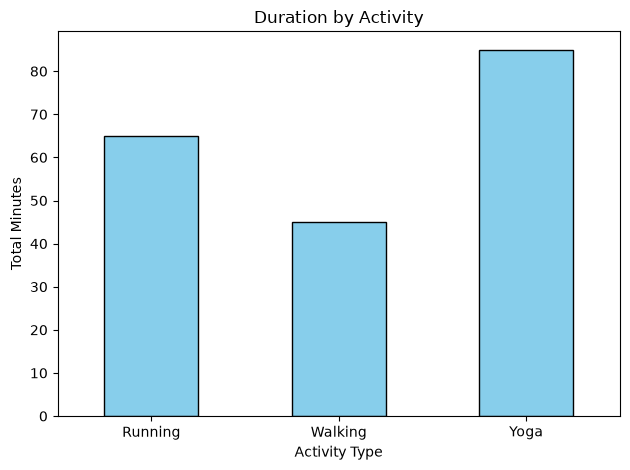

In [ ]:
tracker.df.groupby("Activity_Type")["Duration_Minutes"].sum().plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Duration by Activity")
plt.xlabel("Activity Type")
plt.ylabel("Total Minutes")
plt.xticks(rotation=0)
plt.show()


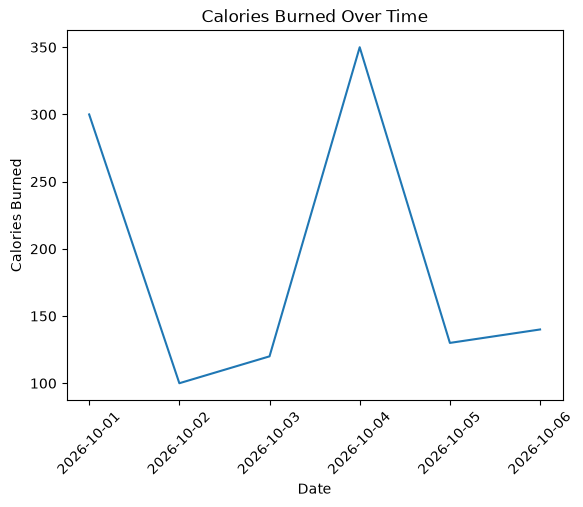

In [13]:
plt.plot(
    tracker.df["Date"],
    tracker.df["Calories_Burned"]
)

plt.title("Calories Burned Over Time")
plt.xlabel("Date")
plt.ylabel("Calories Burned")
plt.xticks(rotation=45)
plt.show()

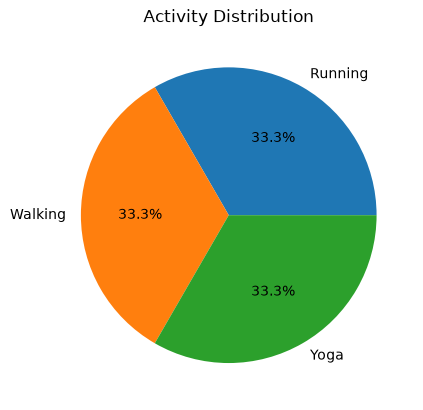

In [14]:
plt.pie(tracker.df["Activity_Type"].value_counts(), labels=tracker.df["Activity_Type"].value_counts().index, autopct="%1.1f%%")

plt.title("Activity Distribution")
plt.show()

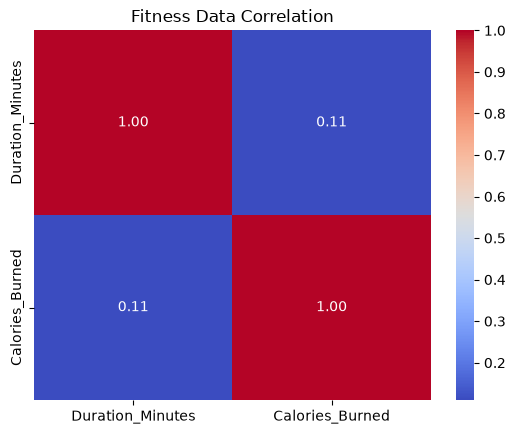

In [15]:
correlation = tracker.df[
    ["Duration_Minutes", "Calories_Burned"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Fitness Data Correlation")
plt.show()

In [16]:
tracker.log_activity("Walking", 30, 150)

Activity added successfully!
